---
authors:
  - name: Emma Pidduck
    url: https://www.linkedin.com/in/emmapidduck/
---

# Day 17 · Light & dark — Light in, heat out

<img src="assets/ECMWF_Core_Logo_RGB.png" width="170" alt="ECMWF logo">

### #30DayMapChallenge 2026 · ECMWF IFS 9 km open data · Map by Emma Pidduck

> ⚠️ **Just for fun — not an official ECMWF product.** Claude (Anthropic) helped build
> these notebooks. They are **not** official ECMWF notebooks and are **not** supported by
> ECMWF — a personal [#30DayMapChallenge](https://30daymapchallenge.com/) experiment.

One instant of the ECMWF forecast, split along the line between day and night.

- **The light side** shows the **sunlight reaching the ground**. Clouds show up as shadows.
- **The dark side** shows the **heat the planet is sending back to space**. The Earth glows
  in the infrared all the time; at night that is the only light there is. Warm, clear ground
  glows brightest and the cold tops of deep clouds are dark.

At 15:00 UTC in mid-November the line runs straight through Europe, so the map also says
which of the national meteorological services of ECMWF's 35 Member and Co-operating States
still have the sun up.

The same recipe, repeated every few minutes, gives a **24-hour animation**: the line sweeps
across the globe and the 35 services go dark one by one, then light up again.

Self-contained: method, code, output, data licence and tools in one place, runnable on any
laptop with `pip`.

## Method

- Fetch two **radiation** fields from the IFS **9 km (0.1°)** open-data forecast: sunlight
  arriving at the surface (`ssrd`) and heat leaving the top of the atmosphere (`ttr`), every
  three hours for the first 24 hours of the run.
- Both are **accumulated** since the start of the forecast, in J m⁻². Subtracting one step
  from the next and dividing by three hours gives the mean flux in W m⁻² over that
  three-hour window. A day is eight windows.
- That is fine for the heat, which changes slowly. It is not fine for the sunlight: in three
  hours the sun moves 45° of longitude, so a three-hour mean has no sharp edge between day
  and night. So the sunlight is rebuilt for the instant:
  1. work out how much sunlight arrived at the **top** of the atmosphere over the same three
     hours (pure geometry);
  2. divide the forecast surface sunlight by it. The result is the share of sunlight that
     made it through the clouds and the air, between 0 and about 0.85;
  3. multiply that share by the sunlight at the top of the atmosphere **at the instant**.
- For any instant, the share and the heat are **blended in time** between the two windows
  whose mid-points sit either side of it. The last window of the day blends back into the
  first, so the animation loops.
- The position of the sun also gives the **day/night line** (sunset, sun 0.83° below the
  horizon) and **civil twilight** (down to 6° below), across which the two sides are blended.
- Draw it on an **orthographic** projection, the view of a sphere from far away, by asking
  PROJ for the longitude and latitude of every pixel and sampling the fields there.

**What this is and is not.** The position of the sun is exact for every frame. The clouds are
not: each frame shows cloud averaged over three to six hours, so fast-moving cloud is
smeared. Close to the day/night line the sunlight is a little too high, because the share
was measured while the sun was higher and the air path shorter; the values there are small
either way. And the loop cheats once: between about 22:30 and 01:30 UTC it fades from the
end of the forecast day back to its start.

## Data

| Dataset | What is used | Licence |
|---|---|---|
| [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data) — IFS forecast (`stream=oper`), 0.1° | surface solar radiation downwards `ssrd` and top net thermal radiation `ttr`; 00 UTC run, +3 h to +24 h every three hours | CC-BY-4.0 |
| [Natural Earth](https://www.naturalearthdata.com) 1:50m | coastlines and country borders | public domain |

No account needed for either. The locations of the 35 national meteorological services are
typed in by hand (the city of each headquarters, to about 0.01°).

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

When you share a map made from this data, attribute it:
`© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use`

Coastlines and borders: [Natural Earth](https://www.naturalearthdata.com) (public domain).

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve the IFS forecast (the ECMWF API client) |
| [`cfgrib`](https://github.com/ecmwf/cfgrib) + `xarray` | read the GRIB (ECMWF's GRIB engine for xarray, built on ecCodes) |
| [`pyproj`](https://pyproj4.github.io/pyproj/) | the orthographic projection, forwards and backwards |
| `scipy` | sampling the fields onto the map |
| `cartopy` | only used to download the Natural Earth lines |
| `matplotlib` | the poster, and the `inferno` colour map for the night side |
| `Pillow` · `ffmpeg` (optional) | the GIF · a crisper MP4 |

```bash
pip install ecmwf-opendata cfgrib xarray pandas pyproj scipy pillow cartopy matplotlib
```

**Learn more:** [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [`ssrd` in the parameter database](https://codes.ecmwf.int/grib/param-db/169) · [`ttr` in the parameter database](https://codes.ecmwf.int/grib/param-db/179) · [Radiation quantities in the ECMWF model](https://www.ecmwf.int/en/elibrary/80755-radiation-quantities-ecmwf-model-and-mars) · [the `inferno` colour map](https://matplotlib.org/stable/users/explain/colors/colormaps.html)

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-opendata cfgrib xarray pandas pyproj scipy pillow cartopy matplotlib

In [2]:
import os, sys, io, contextlib, shutil, subprocess, tempfile, warnings
import numpy as np
import pandas as pd
import xarray as xr
import pyproj
from ecmwf.opendata import Client
from scipy import ndimage as ndi
from PIL import Image
import cartopy.io.shapereader as shpreader
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb, to_rgba
from matplotlib.collections import LineCollection
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]

@contextlib.contextmanager
def quiet():
    "Silence the open-data banner + download progress bars. Real errors still raise."
    py = sys.stderr; sys.stderr = io.StringIO()
    try:
        saved = os.dup(2); dn = os.open(os.devnull, os.O_WRONLY); os.dup2(dn, 2)
    except Exception:
        saved = None
    try:
        yield
    finally:
        sys.stderr = py
        if saved is not None:
            os.dup2(saved, 2); os.close(saved); os.close(dn)

### Configuration

`DATE = 0` pulls **today's** 00Z run, so re-running on **17 November 2026** gives that day's
map with no edits. Pin a day with e.g. `DATE = "20261117"` (delete the GRIB file first, or
change its name, to force a new download). `HOUR` is the instant of the still poster and can
be any time of the day, fractions included; `CLON`/`CLAT` spin the globe.

In [3]:
DATE, TIME   = 0, 0                          # today's 00Z run
HOUR         = 15                            # the instant of the still, hours after the run start
STEPS        = list(range(3, 25, 3))         # +3 h ... +24 h: eight three-hour windows, one day
GRIB         = "data/day17_radiation_24h.grib2"
OUTPNG       = "day17_light_dark.png"
OUTGIF, OUTMP4 = "day17_light_dark.gif", "day17_light_dark.mp4"
AUTHOR       = "Emma Pidduck"
CLON, CLAT   = 14.0, 42.0                    # centre of the globe: the Adriatic
N            = 2400                          # globe size in pixels, still poster
ANIM_W       = 1728                          # animation width in pixels (1728 x 2160, 4:5)
N_ANIM       = 1536                          # globe size in pixels, animation
FRAME_MIN    = 7.5                           # minutes of the day per animation frame
FPS          = 24                            # frames per second: a day in eight seconds
GIF_W, GIF_EVERY = 864, 4                    # GIF width in pixels, and keep every 4th frame (the MP4 has them all)
MP4_LOOPS    = 2                             # days in the MP4 (a GIF loops by itself)
R_EARTH      = 6371008.8                     # metres
S0           = 1361.0                        # the solar constant, W/m2
SUNSET, CIVIL = -0.833, -6.0                 # sun elevation at sunset / end of civil twilight, degrees
BG, INK, MUT = "#ffffff", "#1d2733", "#6b7785"

## Retrieve

Two parameters, eight steps, about 40 MB:
[ssrd = 169](https://codes.ecmwf.int/grib/param-db/169) and
[ttr = 179](https://codes.ecmwf.int/grib/param-db/179). `resol="0p1"` asks for the 9 km
grid; the client defaults to 0.25°. Downloaded to a file so re-runs are reproducible and
offline-friendly.

In [4]:
os.makedirs("data", exist_ok=True)
with quiet():
    if not os.path.exists(GRIB):
        Client("ecmwf").retrieve(date=DATE, time=TIME, step=STEPS, stream="oper", type="fc",
                                 param=["ssrd", "ttr"], resol="0p1", target=GRIB)
print(f"{GRIB}: {os.path.getsize(GRIB) / 1e6:.0f} MB")

data/day17_radiation_24h.grib2: 36 MB


## Reading & processing

The grid is 0.1°, latitude 90 → −90, longitude −180 → 179.9. Both fields count up from the
start of the forecast (zero at step 0), so the difference between one step and the next is
what arrived (or left) in the three hours between them. `ttr` is negative by ECMWF
convention (downward fluxes are positive), so the heat leaving to space is `−ttr`.

In [5]:
ds  = xr.open_dataset(GRIB, engine="cfgrib").sortby("step")
lat = ds["latitude"].values; lon = ds["longitude"].values
assert lat[0] > lat[-1] and lon[0] == -180.0, "unexpected grid orientation"

BASE   = pd.Timestamp(ds["time"].values)
EDGES  = np.r_[0.0, ds["step"].values / np.timedelta64(1, "h")]               # 0, 3, ... 24 h
assert np.allclose(np.diff(EDGES), 3) and EDGES[-1] == 24, "expected three-hourly steps to +24 h"
NW, WINDOW = len(EDGES) - 1, 3 * 3600.0                                        # eight windows of three hours

def at(hour):
    "The UTC time `hour` hours after the start of the run."
    return BASE + pd.Timedelta(hours=float(hour))

VALID  = at(HOUR)
sun_w  = np.diff(ds["ssrd"].values.astype("float32"), axis=0, prepend=0)       # J/m2 reaching the ground, per window
heat_w = -np.diff(ds["ttr"].values.astype("float32"), axis=0, prepend=0) / WINDOW   # W/m2 leaving to space
print(f"run {BASE:%Y-%m-%d %H} UTC · {NW} windows of 3 h · still at {VALID:%H:%M} UTC")
print(f"heat to space {heat_w.min():.0f} to {heat_w.max():.0f} W/m2")

run 2026-11-12 00 UTC · 8 windows of 3 h · still at 15:00 UTC
heat to space 81 to 398 W/m2


### Where is the sun?

Three numbers describe the sun at any moment: its **declination** (the latitude it is
directly above), the **equation of time** (how far the sundial runs ahead of the clock) and
the **Earth–Sun distance**. These are the standard Spencer (1971) series, good to a
fraction of a degree. From them, `cos_zenith` is the height of the sun seen from any point
on Earth: 1 overhead, 0 on the horizon, negative below it.

In [6]:
def sun(t):
    "Declination (radians), equation of time (minutes) and distance factor for a UTC time."
    g = 2 * np.pi / 365 * (t.dayofyear - 1 + (t.hour + t.minute / 60 - 12) / 24)
    eot = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                    - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    dec = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
           + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    dist = (1.00011 + 0.034221 * np.cos(g) + 0.00128 * np.sin(g)
            + 0.000719 * np.cos(2 * g) + 0.000077 * np.sin(2 * g))
    return dec, eot, dist

def cos_zenith(t, la, lo):
    "Cosine of the solar zenith angle at UTC time t, for latitude/longitude in degrees."
    dec, eot, _ = sun(t)
    hour_angle = np.deg2rad((t.hour + t.minute / 60 + t.second / 3600 + eot / 60 - 12) * 15 + lo)
    la = np.deg2rad(la)
    return np.sin(la) * np.sin(dec) + np.cos(la) * np.cos(dec) * np.cos(hour_angle)

def elevation(t, la, lo):
    "Height of the sun above the horizon, degrees."
    return np.rad2deg(np.arcsin(np.clip(cos_zenith(t, la, lo), -1, 1)))

dec, eot, _ = sun(VALID)
SUBLAT, SUBLON = np.rad2deg(dec), -((VALID.hour + VALID.minute / 60 + eot / 60 - 12) * 15)
print(f"at {VALID:%H:%M} UTC the sun is overhead at {abs(SUBLAT):.1f}°{'N' if SUBLAT > 0 else 'S'}, {abs(SUBLON):.1f}°{'E' if SUBLON > 0 else 'W'}")

at 15:00 UTC the sun is overhead at 17.5°S, 48.9°W


### From three-hour totals to one instant

For each window, add up the sunlight at the top of the atmosphere in five-minute slices and
divide the forecast surface total by it. That ratio, the **clearness**, is the share of
sunlight that got through. Where the sun barely rose in a window the ratio is not defined;
those points borrow the nearest defined value and get a `trust` of zero. `trust` rises
smoothly to one where the window had plenty of sun, and the blending in time below leans
on whichever window it trusts more.

In [7]:
clear = np.empty_like(sun_w); trust = np.empty_like(sun_w); DT = 300
for k in range(NW):
    top = np.zeros(sun_w.shape[1:])
    for s in range(int(WINDOW / DT)):
        t = at(EDGES[k]) + pd.Timedelta(seconds=(s + 0.5) * DT)
        top += np.maximum(cos_zenith(t, lat[:, None], lon[None, :]), 0) * (S0 * sun(t)[2] * DT)
    known    = top > 1.5e5                                                     # a mean of 14 W/m2 or more
    ratio    = np.where(known, sun_w[k] / np.maximum(top, 1), np.nan)
    nearest  = ndi.distance_transform_edt(~known, return_distances=False, return_indices=True)
    clear[k] = np.clip(ratio[tuple(nearest)], 0, 0.9)
    trust[k] = np.clip((top - 1.5e5) / 3e6, 0, 1)                              # 0 = not defined ... 1 = plenty of sun
print(f"clearness where the sun was up: median {np.median(clear[trust > 0]):.2f}, clearest 1 % above {np.percentile(clear[trust > 0], 99):.2f}")

clearness where the sun was up: median 0.56, clearest 1 % above 0.89


### The globe

An orthographic map is a square of pixels with a disc in it. For every pixel inside the
disc, PROJ's *inverse* projection gives the longitude and latitude it shows, and the fields
are sampled there (bilinear, with the seam at the date line closed).

`fields(g, hour)` then gives the three things the map needs for any instant: the height of
the sun, the sunlight reaching the ground and the heat leaving to space. Window `k` is
centred on hour `3k + 1.5`; an instant between two centres takes a weighted mix of the two
(for the sunlight, weighted by `trust` as well), and the eighth window wraps round to the first.

In [8]:
P = pyproj.Proj(f"+proj=ortho +lat_0={CLAT} +lon_0={CLON} +R={R_EARTH}")

def canvas(n):
    "An n x n square of pixels and, for those on the globe, where on Earth they are."
    X, Y = np.meshgrid(np.linspace(-R_EARTH, R_EARTH, n), np.linspace(R_EARTH, -R_EARTH, n))
    inside = X**2 + Y**2 < 0.99999 * R_EARTH**2
    plon, plat = P(X[inside], Y[inside], inverse=True)
    return dict(n=n, X=X, Y=Y, inside=inside, lat=plat, lon=plon, cache={},
                rows=(lat[0] - plat) / (lat[0] - lat[1]), cols=((plon - lon[0]) % 360) / (lon[1] - lon[0]))

def sample(g, field, order=1):
    "A field on the 0.1° grid -> the pixels of the globe."
    return ndi.map_coordinates(np.concatenate([field, field[:, :1]], axis=1), [g["rows"], g["cols"]],
                               order=order, mode="nearest")

def window(g, k):
    "Clearness, how far to trust it and the heat for window k, on the pixels of the globe (kept for re-use)."
    if k not in g["cache"]:
        g["cache"][k] = (sample(g, clear[k]), sample(g, trust[k]), sample(g, heat_w[k]))
    return g["cache"][k]

def fields(g, hour):
    "Sun elevation (degrees), sunlight at the ground and heat to space (W/m2) at `hour`, on the globe's pixels."
    x = (hour - 1.5) / 3; a = int(np.floor(x)) % NW; b = (a + 1) % NW; w = x - np.floor(x)
    ca, ta, ha = window(g, a); cb, tb, hb = window(g, b)
    wa, wb = (1 - w) * ta, w * tb                                              # time weight x trust
    share = np.where(wa + wb > 0, (wa * ca + wb * cb) / np.maximum(wa + wb, 1e-9), (1 - w) * ca + w * cb)
    t = at(hour); cz = cos_zenith(t, g["lat"], g["lon"])
    return (np.rad2deg(np.arcsin(np.clip(cz, -1, 1))), share * S0 * sun(t)[2] * np.maximum(cz, 0),
            (1 - w) * ha + w * hb)

G = canvas(N)
_, sunlight, heat_out = fields(G, HOUR)
print(f"{VALID:%H:%M} UTC: sunlight up to {sunlight.max():.0f} W/m2 · heat to space {heat_out.min():.0f} to {heat_out.max():.0f} W/m2")

15:00 UTC: sunlight up to 1045 W/m2 · heat to space 104 to 344 W/m2


### Colour — and why it is colourblind-safe

Two sequential ramps, one per side. The **day** ramp runs from slate blue (little sunlight:
thick cloud or a low sun) to pale yellow and white. The **night** ramp is matplotlib's
**`inferno`**, cut off at 80 % so it ends at amber instead of pale yellow: against a white
page the top of the full ramp would look like daylight. `inferno` is perceptually uniform
and colourblind-safe by design. The cell **validates** that each ramp is monotonic in
luminance, so each reads correctly for every form of colour-vision deficiency and in
greyscale.

`paint` turns the three fields into the picture: day colours where the sun is up, night
colours where it is down, and a smooth blend across the twilight band.

In [9]:
DAY   = LinearSegmentedColormap.from_list("day",   ["#56708f", "#7f9db8", "#a9c5d6", "#d3e2df",
                                                    "#f1ecc9", "#fff2a8", "#fffdf2"])
NIGHT = LinearSegmentedColormap.from_list("night", plt.get_cmap("inferno")(np.linspace(0, 0.8, 256)))
DAY_NORM, NIGHT_NORM = Normalize(0, 900), Normalize(120, 320)                 # W/m2

def luminance(cmap, n=256):
    rgb = cmap(np.linspace(0, 1, n))[:, :3]
    return 0.2126 * rgb[:, 0] + 0.7152 * rgb[:, 1] + 0.0722 * rgb[:, 2]

for name, cmap in (("day", DAY), ("night", NIGHT)):
    L = luminance(cmap)
    print(f"{name:5s} luminance-monotonic: {bool((np.diff(L) >= -1e-3).all())}   ({L[0]:.2f} -> {L[-1]:.2f})")

def paint(g, hour):
    "The globe at `hour` as an RGBA image, plus the sun elevation on the same pixels (for the day/night line)."
    elev, sunlight, heat = fields(g, hour)
    w = np.clip((elev - CIVIL) / (SUNSET - CIVIL), 0, 1); w = (w * w * (3 - 2 * w))[:, None]   # 1 = day, 0 = night
    rgb = DAY(DAY_NORM(sunlight))[:, :3] * w + NIGHT(NIGHT_NORM(heat))[:, :3] * (1 - w)
    img = np.ones((g["n"], g["n"], 4)); img[..., 3] = 0
    img[g["inside"]] = np.column_stack([rgb, np.ones(len(rgb))])
    el = np.full((g["n"], g["n"]), np.nan); el[g["inside"]] = elev
    return img, el

day   luminance-monotonic: True   (0.43 -> 0.99)
night luminance-monotonic: True   (0.00 -> 0.67)


### Who still has the sun?

ECMWF has **23 Member States** and **12 Co-operating States**. Each is placed at the home
city of its national meteorological service and sorted into daylight, civil twilight or
night. They are listed in the order the sun sets on them on the day of the forecast, so on
the poster the list goes dark from its first name to its last.

In [10]:
SERVICES = [  # state, city of the national meteorological service, latitude, longitude
    ("Austria", "Vienna", 48.25, 16.36), ("Belgium", "Uccle", 50.80, 4.36), ("Croatia", "Zagreb", 45.82, 15.98),
    ("Denmark", "Copenhagen", 55.72, 12.56), ("Estonia", "Tallinn", 59.42, 24.69), ("Finland", "Helsinki", 60.20, 24.96),
    ("France", "Saint-Mandé", 48.84, 2.42), ("Germany", "Offenbach", 50.10, 8.75), ("Greece", "Athens", 37.89, 23.74),
    ("Iceland", "Reykjavík", 64.13, -21.90), ("Ireland", "Dublin", 53.37, -6.27), ("Italy", "Rome", 41.90, 12.50),
    ("Luxembourg", "Findel", 49.63, 6.21), ("Netherlands", "De Bilt", 52.10, 5.18), ("Norway", "Oslo", 59.94, 10.72),
    ("Portugal", "Lisbon", 38.77, -9.13), ("Serbia", "Belgrade", 44.80, 20.47), ("Slovenia", "Ljubljana", 46.07, 14.51),
    ("Spain", "Madrid", 40.45, -3.72), ("Sweden", "Norrköping", 58.58, 16.15), ("Switzerland", "Zürich", 47.45, 8.56),
    ("Türkiye", "Ankara", 39.97, 32.86), ("United Kingdom", "Exeter", 50.73, -3.47),
    ("Bulgaria", "Sofia", 42.65, 23.38), ("Czech Republic", "Prague", 50.01, 14.45), ("Georgia", "Tbilisi", 41.72, 44.79),
    ("Hungary", "Budapest", 47.51, 19.03), ("Israel", "Bet Dagan", 32.00, 34.81), ("Latvia", "Riga", 56.95, 24.11),
    ("Lithuania", "Vilnius", 54.69, 25.28), ("Montenegro", "Podgorica", 42.44, 19.26), ("Morocco", "Casablanca", 33.57, -7.66),
    ("North Macedonia", "Skopje", 42.00, 21.43), ("Romania", "Bucharest", 44.51, 26.08), ("Slovakia", "Bratislava", 48.17, 17.11),
]
assert len(SERVICES) == 35
svc = pd.DataFrame(SERVICES, columns=["state", "city", "lat", "lon"])

# the last minute of daylight for each service, to put them in sunset order
minutes = np.arange(0, 24, 1 / 60)
up = np.array([elevation(at(h), svc["lat"].values, svc["lon"].values) > SUNSET for h in minutes])
assert up.any(axis=0).all() and not up[0].any() and not up[-1].any(), "a service has no sunset inside the UTC day"
svc["sunset"] = [minutes[up[:, j]].max() for j in range(len(svc))]
svc = svc.sort_values("sunset").reset_index(drop=True)

def status(hour):
    "Where the sun is for each service at `hour`: 'day', 'twilight' or 'night'."
    e = elevation(at(hour), svc["lat"].values, svc["lon"].values)
    return np.where(e > SUNSET, "day", np.where(e > CIVIL, "twilight", "night"))

svc["sunset UTC"] = [f"{at(h):%H:%M}" for h in svc["sunset"]]
svc["sun °"]  = elevation(VALID, svc["lat"].values, svc["lon"].values).round(1)
svc["where"]  = status(HOUR)
print(f"{VALID:%H:%M} UTC:", svc.groupby("where", sort=False)["state"].count().to_dict())
svc[["state", "city", "sunset UTC", "sun °", "where"]]

15:00 UTC: {'night': 3, 'twilight': 7, 'day': 25}


,state,city,sunset UTC,sun °,where
0,Georgia,Tbilisi,13:44,-14.3,night
1,Finland,Helsinki,13:59,-7.5,night
2,Estonia,Tallinn,14:04,-7.0,night
3,Latvia,Riga,14:19,-5.8,twilight
4,Lithuania,Vilnius,14:24,-5.5,twilight
5,Türkiye,Ankara,14:36,-5.1,twilight
6,Sweden,Norrköping,14:42,-2.7,twilight
7,Israel,Bet Dagan,14:43,-4.1,twilight
8,Romania,Bucharest,14:52,-2.0,twilight
9,Norway,Oslo,14:57,-1.1,twilight


## Render

The globe is a square with a disc in it, which leaves four empty corners: the title, the
logo and the two colour scales go there. Coastlines and borders are drawn dark on the day
side and pale on the night side, changing across the twilight band like everything else.

`poster` builds everything that does not change with time once, and hands back an `update`
function that redraws what does: the globe, the lines, the dots, the list and the clock.
The still is one call to it; the animation is 192.

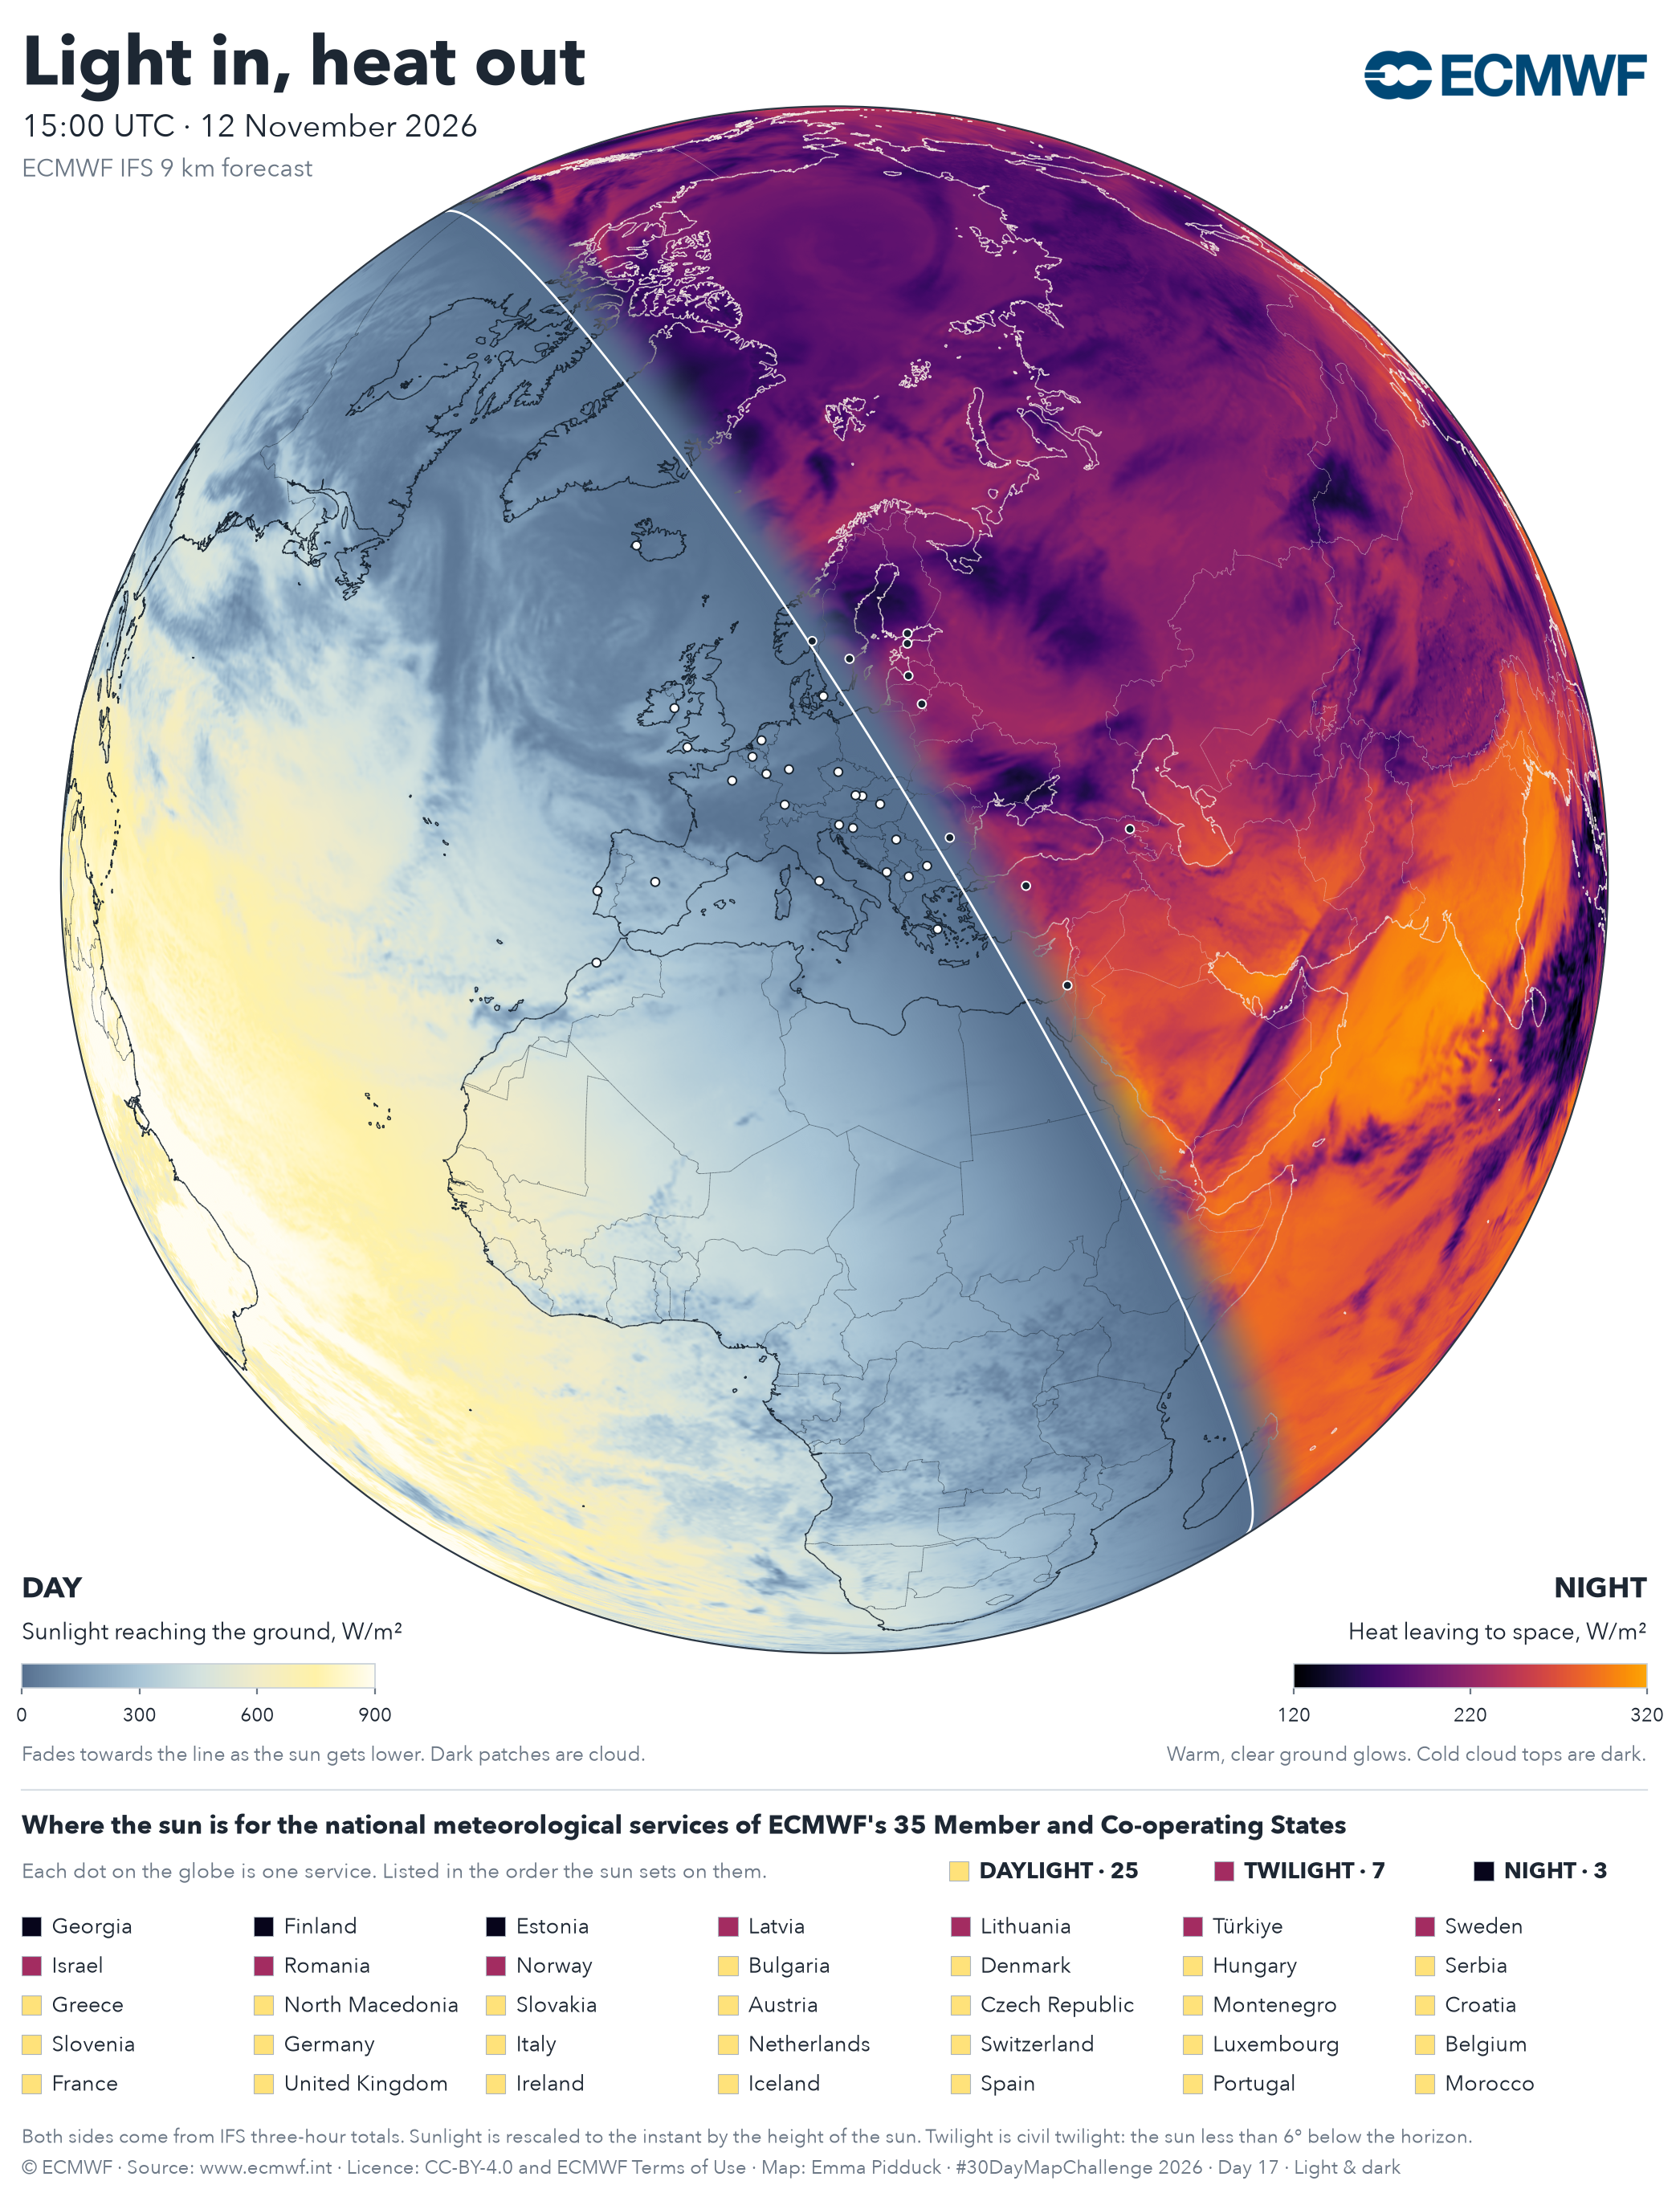

In [11]:
def segments(geoms):
    "Natural Earth lines -> an array of [x0, y0, x1, y1, lon0, lat0, lon1, lat1] for the pieces on this side of the globe."
    out = []
    for geom in geoms:
        for part in getattr(geom, "geoms", [geom]):
            c = np.asarray(part.coords)[:, :2]
            x, y = P(c[:, 0], c[:, 1]); ok = np.isfinite(x) & np.isfinite(y)   # far side -> inf
            a = np.flatnonzero(ok[:-1] & ok[1:])
            out.append(np.column_stack([x[a], y[a], x[a + 1], y[a + 1], c[a], c[a + 1]]))
    return np.vstack(out)

ne = lambda cat, name: list(shpreader.Reader(shpreader.natural_earth("50m", cat, name)).geometries())
BORDERS, COAST = segments(ne("cultural", "admin_0_boundary_lines_land")), segments(ne("physical", "coastline"))
LABEL  = {"day": "DAYLIGHT", "twilight": "TWILIGHT", "night": "NIGHT"}
SWATCH = {"day": to_rgba("#ffe27a"), "twilight": NIGHT(0.55), "night": NIGHT(0.06)}
COLS   = 7                                                                    # 35 names = 7 columns x 5 rows

def scale(fig, x, cmap, norm, ticks, head, title, note, right=False):
    "A small colour scale in a bottom corner of the globe's square."
    cax = fig.add_axes([x, 0.236, 0.20, 0.011])
    cb = fig.colorbar(ScalarMappable(norm, cmap), cax=cax, orientation="horizontal", ticks=ticks)
    cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)
    cb.ax.tick_params(color=MUT, labelsize=8.5, labelcolor=INK, length=3)
    tx, ha = (x + 0.20, "right") if right else (x, "left")
    fig.text(tx, 0.277, head, color=INK, fontsize=13, fontweight="bold", ha=ha)
    fig.text(tx, 0.258, title, color=INK, fontsize=10.5, ha=ha)
    fig.text(tx, 0.203, note, color=MUT, fontsize=9, ha=ha)

def poster(g, dpi):
    "Build the poster for the canvas `g`. Returns the figure and update(hour), which redraws it for an instant."
    fig = plt.figure(figsize=(11, 13.75), dpi=dpi); fig.patch.set_facecolor(BG)
    ax = fig.add_axes([0.06, 0.25, 0.88, 0.704]); ax.set_axis_off(); ax.set_aspect("equal")
    im = ax.imshow(np.zeros((2, 2, 4)), extent=[-R_EARTH, R_EARTH, -R_EARTH, R_EARTH], interpolation="lanczos", zorder=1)
    lines = []
    for seg, width, a_day, a_night, z in ((BORDERS, 0.3, 0.45, 0.35, 3), (COAST, 0.55, 0.75, 0.60, 4)):
        lc = LineCollection(seg[:, :4].reshape(-1, 2, 2), linewidths=width, zorder=z, capstyle="round")
        ax.add_collection(lc); lines.append((lc, seg, a_day, a_night))
    ax.add_patch(plt.Circle((0, 0), R_EARTH, fc="none", ec="#2b3642", lw=0.8, zorder=7))
    dots = ax.scatter(*P(svc["lon"].values, svc["lat"].values), s=15, lw=0.7, zorder=8)
    ax.set_xlim(-1.005 * R_EARTH, 1.005 * R_EARTH); ax.set_ylim(-1.005 * R_EARTH, 1.005 * R_EARTH)

    # the four corners
    fig.text(0.04, 0.972, "Light in, heat out", color=INK, fontsize=31, fontweight="bold", va="center")
    clock = fig.text(0.04, 0.943, "", color=INK, fontsize=14, va="center")
    fig.text(0.04, 0.924, "ECMWF IFS 9 km forecast", color=MUT, fontsize=11, va="center")
    logo = mpimg.imread("assets/ECMWF_Core_Logo_RGB.png")
    lax = fig.add_axes([0.80, 0.955, 0.16, 0.16 * logo.shape[0] / logo.shape[1] * 11 / 13.75], anchor="NE")
    lax.imshow(logo); lax.set_axis_off()
    scale(fig, 0.04, DAY, DAY_NORM, [0, 300, 600, 900], "DAY", "Sunlight reaching the ground, W/m²",
          "Fades towards the line as the sun gets lower. Dark patches are cloud.")
    scale(fig, 0.76, NIGHT, NIGHT_NORM, [120, 220, 320], "NIGHT", "Heat leaving to space, W/m²",
          "Warm, clear ground glows. Cold cloud tops are dark.", right=True)

    # who still has the sun: a fixed grid of 35 names in sunset order, each with a square that changes colour
    fig.add_artist(plt.Line2D([0.04, 0.96], [0.190, 0.190], color="#d9dfe5", lw=0.8))
    fig.text(0.04, 0.170, "Where the sun is for the national meteorological services of ECMWF's 35 Member and Co-operating States",
             color=INK, fontsize=11.5, fontweight="bold")
    fig.text(0.04, 0.153, "Each dot on the globe is one service. Listed in the order the sun sets on them.",
             color=MUT, fontsize=9.5, va="center")
    counts = {}
    for key, x in (("day", 0.565), ("twilight", 0.715), ("night", 0.862)):
        fig.add_artist(plt.Rectangle((x, 0.153 - 0.0044), 0.011, 0.0088, fc=SWATCH[key], ec="#aab4be", lw=0.4))
        counts[key] = fig.text(x + 0.017, 0.153, "", color=INK, fontsize=10, fontweight="bold", va="center")
    squares = []
    for i, name in enumerate(svc["state"]):
        x, y = 0.04 + (i % COLS) * 0.92 / COLS, 0.128 - (i // COLS) * 0.0178
        squares.append(fig.add_artist(plt.Rectangle((x, y - 0.0044), 0.011, 0.0088, ec="#aab4be", lw=0.4)))
        fig.text(x + 0.017, y, name, color=INK, fontsize=9.8, va="center")

    fig.text(0.04, 0.030, "Both sides come from IFS three-hour totals. Sunlight is rescaled to the instant by the height of the sun. "
             "Twilight is civil twilight: the sun less than 6° below the horizon.", color=MUT, fontsize=8.8)
    fig.text(0.04, 0.016, f"© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use · Map: {AUTHOR} · "
             "#30DayMapChallenge 2026 · Day 17 · Light & dark", color=MUT, fontsize=8.8)

    dark, pale, white = np.array(to_rgb("#16222e")), np.array(to_rgb("#f3e9e2")), np.ones(3)
    line = []                                                                  # the current day/night line

    def update(hour):
        t = at(hour)
        img, el = paint(g, hour); im.set_data(img)
        for lc, seg, a_day, a_night in lines:                                  # dark where it is day, pale where it is night
            e = 0.5 * (elevation(t, seg[:, 5], seg[:, 4]) + elevation(t, seg[:, 7], seg[:, 6]))
            wd = np.clip((e - CIVIL) / (SUNSET - CIVIL), 0, 1)[:, None]
            lc.set_color(np.hstack([dark * wd + pale * (1 - wd), a_day * wd + a_night * (1 - wd)]))
        while line:
            line.pop().remove()
        line.append(ax.contour(g["X"], g["Y"], el, levels=[SUNSET], colors=["#ffffff"], linewidths=1.0, linestyles="solid", zorder=5))
        where = status(hour); lit = (where == "day")[:, None]
        dots.set_facecolor(np.where(lit, white, dark)); dots.set_edgecolor(np.where(lit, dark, white))
        for sq, wh in zip(squares, where):
            sq.set_facecolor(SWATCH[wh])
        for key, txt in counts.items():
            txt.set_text(f"{LABEL[key]} · {(where == key).sum()}")
        clock.set_text(f"{t:%H:%M} UTC · {t:%-d %B %Y}")

    return fig, update

fig, update = poster(G, dpi=200)
update(HOUR)
fig.savefig(OUTPNG, facecolor=BG)
plt.show()

## Animate

The same poster, redrawn every seven and a half minutes of the forecast day: 192 frames,
played at 24 a second, so a day takes eight seconds. The sun's position is recomputed for every frame; the
cloud and the heat glide between the eight three-hour windows. Because the last window
blends back into the first, the GIF loops without a jump.

In [12]:
def render_frames(folder):
    "Draw every frame of the day and save it as a PNG in `folder`. Returns the number of frames."
    fig, update = poster(canvas(N_ANIM), dpi=ANIM_W / 11)
    hours = np.arange(0, 24, FRAME_MIN / 60)
    for j, hour in enumerate(hours):
        update(hour); fig.canvas.draw()
        Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3]).save(f"{folder}/{j:04d}.png", compress_level=1)
    plt.close(fig)
    return len(hours)

def write_anim(folder, n, gif_path, mp4_path):
    "MP4 with ffmpeg if it is installed (all frames, full size); GIF with Pillow (fewer, smaller frames, 256 colours)."
    if shutil.which("ffmpeg"):
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-framerate", str(FPS), "-i", f"{folder}/%04d.png",
                        "-vf", f"loop=loop={MP4_LOOPS - 1}:size={n}:start=0,scale=trunc(iw/2)*2:trunc(ih/2)*2",
                        "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "17", "-movflags", "+faststart", mp4_path], check=True)
        print(f"{mp4_path}: {n} frames x {MP4_LOOPS}, {os.path.getsize(mp4_path) / 1e6:.1f} MB")
    small = []
    for j in range(0, n, GIF_EVERY):
        f = Image.open(f"{folder}/{j:04d}.png")
        small.append(f.resize((GIF_W, round(GIF_W * f.height / f.width)), Image.LANCZOS))
    spread = np.hstack([np.asarray(small[i]) for i in range(0, len(small), len(small) // 4)])   # night, dawn, noon, dusk
    pal = Image.fromarray(spread).quantize(colors=256, method=Image.Quantize.MEDIANCUT)       # one palette: no flicker
    gif = [s.quantize(palette=pal, dither=Image.Dither.FLOYDSTEINBERG) for s in small]        # dither hides the colour steps
    gif[0].save(gif_path, save_all=True, append_images=gif[1:], duration=GIF_EVERY * 1000 // FPS, loop=0, optimize=True)
    print(f"{gif_path}: {len(gif)} frames, {os.path.getsize(gif_path) / 1e6:.1f} MB")

with tempfile.TemporaryDirectory() as tmp:
    write_anim(tmp, render_frames(tmp), OUTGIF, OUTMP4)

day17_light_dark.mp4: 192 frames x 2, 15.8 MB


day17_light_dark.gif: 48 frames, 13.7 MB


![A day in eight seconds: the line between day and night sweeps across a globe centred on Europe, sunlight on the day side and outgoing heat on the night side, while the list of 35 national meteorological services goes dark and lights up again](day17_light_dark.gif)

*Sharper and smoother MP4: [`day17_light_dark.mp4`](day17_light_dark.mp4) · ECMWF IFS forecast, open data (CC-BY-4.0).*

## Note

The two sides are two views of the same weather, not two columns of one account. The day
side is the sunlight that reaches the **ground**: what is left after clouds and the air
have reflected and absorbed their share. The night side is the heat leaving the **top of
the atmosphere**. Averaged over the globe and the year, what balances that outgoing heat is
all the sunlight the planet absorbs, in the air as well as at the ground. That field is not
in the open data, so the numbers on the two scales are not meant to add up.

The contrast between the sides is real, though. Sunlight only arrives on the half facing
the sun, and most of it near the point where the sun is overhead. Heat leaves from
everywhere, day and night, at a far more even rate: the night-side scale spans less than a
factor of three, the day-side scale runs from nothing to 900 W m⁻².

On the night side, the brightest places are warm and cloud-free, because the heat escapes
from the ground or from low in the atmosphere. Deep clouds are dark because their tops are
high and cold. This is the same reason clouds look white on an infrared satellite image,
which is conventionally shown with the colours reversed.

*Part of a #30DayMapChallenge 2026 series built on ECMWF open data.*